# Optical unitary decomposition: Reck vs Clements (improved, self-contained)

One notebook replaces the three originals (*Optical decomposition from scratch*, *Photonic Neural Net decomposition*, *Clements decomposition*). Everything runs with **NumPy + Matplotlib only** (SciPy only for one comparison cell) – no `git clone`, no `pip install pnn`, no network.

**What changed in the algorithm / code**

| Original | Now |
|---|---|
| MZI settings found with BFGS (`scipy.optimize`), or by hand in several copies of the code | **Closed-form** `mzi_null` (exact, no optimiser, no starting point) |
| Reck: nulling only; Clements: needed the `pnn` package and its hidden source | **Both implemented from scratch** with *one* output format: `U = D · T₁ ⋯ T_K` |
| Clements' left→right conversion hand-waved / done inside `pnn` | `factor_2x2`: **closed-form** `T⁻¹ D = D′ T′` (the actual Clements trick) |
| Right-elimination was wrong in the first attempt (`.T` instead of `.conj().T`) and patched in a later cell | One tested `_right` routine |
| Loss sign convention `Lp_dB = -loss` (the first loss plot used `+loss` and gave nonsense) | Loss is a **positive dB number**, documented loss model |
| 200 Monte-Carlo trials in nested Python loops (the `1000` cell was never re-run) | **Vectorised**: 5 000 trials in milliseconds, standard errors, *common random numbers* for a paired Reck–Clements comparison |
| Only N = 3, 4 | Validated for N = 2…16, special matrices, plus a new **scaling study** up to N = 32 |

## 0. The library

This cell is also shipped as `photonic_mesh.py` (identical code) so you can `import` it elsewhere.

In [1]:
"""
photonic_mesh.py  --  Reck / Clements decomposition of unitaries into MZI meshes.

Self-contained (NumPy only; no `pnn` package, no git clone, no network).

Conventions
-----------
Phase shifter   P(x)         = diag(exp(i x), 1)
Balanced coupler B           = [[1, i], [i, 1]] / sqrt(2)
Mach-Zehnder    T(theta,phi) = B @ P(theta) @ B @ P(phi)
                             = i e^{i theta/2} [[ s e^{i phi},  c ],
                                                [ c e^{i phi}, -s ]]
                with s = sin(theta/2), c = cos(theta/2)

Every decomposition has the SAME output format

        U = diag(exp(i * alphas)) @ T_1 @ T_2 @ ... @ T_K

where T_k = T(theta_k, phi_k) acts on the neighbouring modes (m_k, m_k+1).
Light enters on the right (T_K first) and leaves through the output phase
screen D on the left.  Reck uses K = N(N-1)/2 MZIs in a triangle (depth 2N-3),
Clements uses the same number in a rectangle (depth N).
"""
from __future__ import annotations

from dataclasses import dataclass
import numpy as np

_B = np.array([[1, 1j], [1j, 1]], dtype=complex) / np.sqrt(2)
_EPS = 1e-12


# --------------------------------------------------------------------------- #
# 1.  Optical building blocks
# --------------------------------------------------------------------------- #
def coupler() -> np.ndarray:
    return _B.copy()


def P(x):
    """Phase shifter on the upper arm."""
    return np.diag([np.exp(1j * x), 1.0]).astype(complex)


def mzi(theta, phi) -> np.ndarray:
    """Ideal MZI  B P(theta) B P(phi)  (closed form, exactly unitary)."""
    s, c = np.sin(theta / 2), np.cos(theta / 2)
    g = 1j * np.exp(1j * theta / 2)
    return g * np.array([[s * np.exp(1j * phi), c],
                         [c * np.exp(1j * phi), -s]])


def random_unitary(n: int, rng=None) -> np.ndarray:
    """Haar-distributed unitary (QR of a Ginibre matrix + phase fix)."""
    rng = np.random.default_rng(rng)
    A = rng.normal(size=(n, n)) + 1j * rng.normal(size=(n, n))
    Q, R = np.linalg.qr(A)
    d = np.diag(R)
    return Q * (d / np.abs(d))


# --------------------------------------------------------------------------- #
# 2.  Closed-form 2x2 solvers (replace the numerical BFGS search)
# --------------------------------------------------------------------------- #
def mzi_null(a, b, which: int = 1):
    """
    (theta, phi) such that  T(theta, phi) @ [a, b]  has output `which` equal to 0.
    The surviving output has magnitude hypot(|a|, |b|).
    """
    aa, bb = abs(a), abs(b)
    if aa < _EPS and bb < _EPS:
        return 0.0, 0.0
    if which == 1:
        return 2 * np.arctan2(aa, bb), np.angle(b) - np.angle(a)
    return 2 * np.arctan2(bb, aa), np.angle(b) - np.angle(a) + np.pi


def optical_elimination(a, b):
    """
    Two-mode block (T followed by an output phase) taking [a, b] -> [r, 0] with
    r = hypot(|a|, |b|) real and positive.  Returns (matrix, (theta, phi, gamma)).
    """
    theta, phi = mzi_null(a, b, 1)
    T = mzi(theta, phi)
    c = (T @ np.array([a, b]))[0]
    gamma = -np.angle(c) if abs(c) > _EPS else 0.0
    return P(gamma) @ T, (theta, phi, gamma)


def factor_2x2(W):
    """
    Closed-form factorisation of any 2x2 unitary  W = diag(e1, e2) @ T(theta, phi).
    Returns (e1, e2, theta, phi).  Numerically stable also for theta -> 0, pi.
    """
    theta = 2 * np.arctan2(abs(W[0, 0]), abs(W[0, 1]))
    s, c = np.sin(theta / 2), np.cos(theta / 2)
    g = 1j * np.exp(1j * theta / 2)
    if s < _EPS or c < _EPS:                      # bar / cross state: phi is free
        phi = 0.0
    else:
        phi = np.angle(W[0, 0]) - np.angle(W[0, 1])
    ephi = np.exp(1j * phi)
    if c >= s:
        e1 = W[0, 1] / (c * g)
        e2 = W[1, 0] / (c * g * ephi)
    else:
        e1 = W[0, 0] / (s * g * ephi)
        e2 = -W[1, 1] / (s * g)
    return e1, e2, theta, phi


# --------------------------------------------------------------------------- #
# 3.  Mesh container
# --------------------------------------------------------------------------- #
@dataclass
class Mesh:
    n: int
    modes: np.ndarray      # (K,) upper mode index m of each MZI (acts on m, m+1)
    thetas: np.ndarray     # (K,)
    phis: np.ndarray       # (K,)
    alphas: np.ndarray     # (N,) output phase screen
    name: str = ""

    @property
    def K(self) -> int:
        return len(self.modes)

    def matrix(self, **loss) -> np.ndarray:
        return reconstruct(self, **loss)

    def layers(self) -> np.ndarray:
        """ASAP schedule: layer index (0-based) of every MZI (light order)."""
        last = np.zeros(self.n, dtype=int)
        out = np.zeros(self.K, dtype=int)
        for k in range(self.K - 1, -1, -1):          # light enters at k = K-1
            m = self.modes[k]
            out[k] = max(last[m], last[m + 1])
            last[m] = last[m + 1] = out[k] + 1
        return out

    @property
    def depth(self) -> int:
        return int(self.layers().max()) + 1 if self.K else 0


# --------------------------------------------------------------------------- #
# 4.  Forward model (vectorised over phase-error trials, optional loss)
# --------------------------------------------------------------------------- #
def _lin(loss_dB):
    return 10.0 ** (-np.asarray(loss_dB, dtype=float) / 10.0)


def reconstruct(mesh: Mesh, thetas=None, phis=None, Lc_dB=0.0, Lp_dB=0.0,
                mzi_loss_dB=0.0):
    """
    Build the transfer matrix of the mesh.

    thetas/phis may be (K,) or (B, K); a batch gives a (B, N, N) result, which
    is how the Monte-Carlo studies avoid Python loops over trials.

    Loss model (loss values are POSITIVE dB):
      * every directional coupler transmits a power fraction 10^(-Lc_dB/10)
      * every phase shifter attenuates the arm it sits on by 10^(-Lp_dB/10)
      * mzi_loss_dB is a shortcut: total coupler loss per MZI, split evenly over its
        two couplers (== Lc_dB = mzi_loss_dB / 2).  This is the model that
        reproduces the pnn-based numbers of the original Clements notebook.
    """
    Lc_dB = np.asarray(Lc_dB, dtype=float) + np.asarray(mzi_loss_dB, dtype=float) / 2
    th = mesh.thetas if thetas is None else thetas
    ph = mesh.phis if phis is None else phis
    th, ph = np.atleast_2d(th), np.atleast_2d(ph)
    Bn = th.shape[0]
    N = mesh.n
    ac = np.sqrt(_lin(Lc_dB))                    # amplitude factor / coupler
    ap = np.sqrt(_lin(Lp_dB))                    # amplitude factor / shifter arm
    Bc = ac * _B

    M = np.broadcast_to(np.eye(N, dtype=complex), (Bn, N, N)).copy()
    for k in range(mesh.K - 1, -1, -1):
        m = mesh.modes[k]
        Pt = np.zeros((Bn, 2, 2), complex)
        Pp = np.zeros((Bn, 2, 2), complex)
        Pt[:, 0, 0], Pt[:, 1, 1] = ap * np.exp(1j * th[:, k]), 1.0
        Pp[:, 0, 0], Pp[:, 1, 1] = ap * np.exp(1j * ph[:, k]), 1.0
        T = Bc @ Pt @ Bc @ Pp                      # (B, 2, 2)
        M[:, m:m + 2, :] = T @ M[:, m:m + 2, :]
    M = np.exp(1j * mesh.alphas)[None, :, None] * M
    return M[0] if Bn == 1 else M


# --------------------------------------------------------------------------- #
# 5.  Decompositions
# --------------------------------------------------------------------------- #
def _left(M, m, col):
    """Null M[m+1, col] with an MZI on rows (m, m+1); update M in place."""
    th, ph = mzi_null(M[m, col], M[m + 1, col], which=1)
    M[m:m + 2, :] = mzi(th, ph) @ M[m:m + 2, :]
    return th, ph


def _right(M, row, col):
    """Null M[row, col] with an MZI on columns (col, col+1); update M in place."""
    # (r T^dagger)[0] = 0   <=>   T r^dagger has first component 0
    th, ph = mzi_null(np.conj(M[row, col]), np.conj(M[row, col + 1]), which=0)
    M[:, col:col + 2] = M[:, col:col + 2] @ mzi(th, ph).conj().T
    return th, ph


def _push_diagonal_left(d, left_ops):
    """Rewrite  T_1^† ... T_k^† D  as  D' T'_1 ... T'_k  (Clements' trick)."""
    d = d.copy()
    out = []
    for m, th, ph in reversed(left_ops):
        W = mzi(th, ph).conj().T @ np.diag(d[m:m + 2])
        e1, e2, th2, ph2 = factor_2x2(W)
        d[m], d[m + 1] = e1, e2
        out.append((m, th2, ph2))
    return d, out[::-1]


def _pack(n, ops, d, name):
    ops = np.array(ops, dtype=float).reshape(-1, 3)
    wrap = lambda x: np.mod(x, 2 * np.pi)
    return Mesh(n, ops[:, 0].astype(int), wrap(ops[:, 1]), wrap(ops[:, 2]),
                np.angle(d), name)


def decompose_reck(U) -> Mesh:
    U = np.asarray(U, dtype=complex)
    n = U.shape[0]
    M, left = U.copy(), []
    for col in range(n - 1):
        for r in range(n - 1, col, -1):
            th, ph = _left(M, r - 1, col)
            left.append((r - 1, th, ph))
    d, ops = _push_diagonal_left(np.diag(M), left)
    return _pack(n, ops, d, "Reck")


def decompose_clements(U) -> Mesh:
    U = np.asarray(U, dtype=complex)
    n = U.shape[0]
    M, left, right = U.copy(), [], []
    for i in range(n - 1):
        if i % 2 == 0:
            for j in range(i + 1):
                row, col = n - 1 - j, i - j
                th, ph = _right(M, row, col)
                right.append((col, th, ph))
        else:
            for j in range(i + 1):
                row, col = n - i + j - 1, j
                th, ph = _left(M, row - 1, col)
                left.append((row - 1, th, ph))
    d, ops = _push_diagonal_left(np.diag(M), left)
    # U = D' T'_left ... T'_right_last ... T_right_first
    ops = ops + right[::-1]
    return _pack(n, ops, d, "Clements")


# --------------------------------------------------------------------------- #
# 6.  Metrics
# --------------------------------------------------------------------------- #
def fidelity(U, A):
    """Normalised matrix fidelity |tr(U^† A)|^2 / (|U|_F^2 |A|_F^2); batch-aware."""
    A = np.asarray(A)
    num = np.abs(np.einsum("ij,...ij->...", U.conj(), A)) ** 2
    den = np.linalg.norm(U) ** 2 * np.sum(np.abs(A) ** 2, axis=(-2, -1))
    return num / den


def transmission(A):
    """Mean output power for unit-power single-mode inputs."""
    A = np.asarray(A)
    return np.sum(np.abs(A) ** 2, axis=(-2, -1)) / A.shape[-1]


def unitarity_error(A):
    A = np.asarray(A)
    I = np.eye(A.shape[-1])
    return np.linalg.norm(np.swapaxes(A.conj(), -1, -2) @ A - I, axis=(-2, -1))


# --------------------------------------------------------------------------- #
# 7.  Small helper used by the tutorial notebook
# --------------------------------------------------------------------------- #
def embed(T, n: int, m: int) -> np.ndarray:
    """Embed a 2x2 block T on modes (m, m+1) of an n-mode identity."""
    G = np.eye(n, dtype=complex)
    G[m:m + 2, m:m + 2] = T
    return G

In [2]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

## 1. Optical building blocks

A balanced coupler `B` mixes two modes 50/50; an MZI is `T(θ, φ) = B · P(θ) · B · P(φ)`. The **internal phase θ** sets the splitting ratio, the **external phase φ** only shifts phases.

Coupler output field : [0.7071+0.j     0.    +0.7071j]
Output powers        : [0.5 0.5]  total = 0.9999999999999998


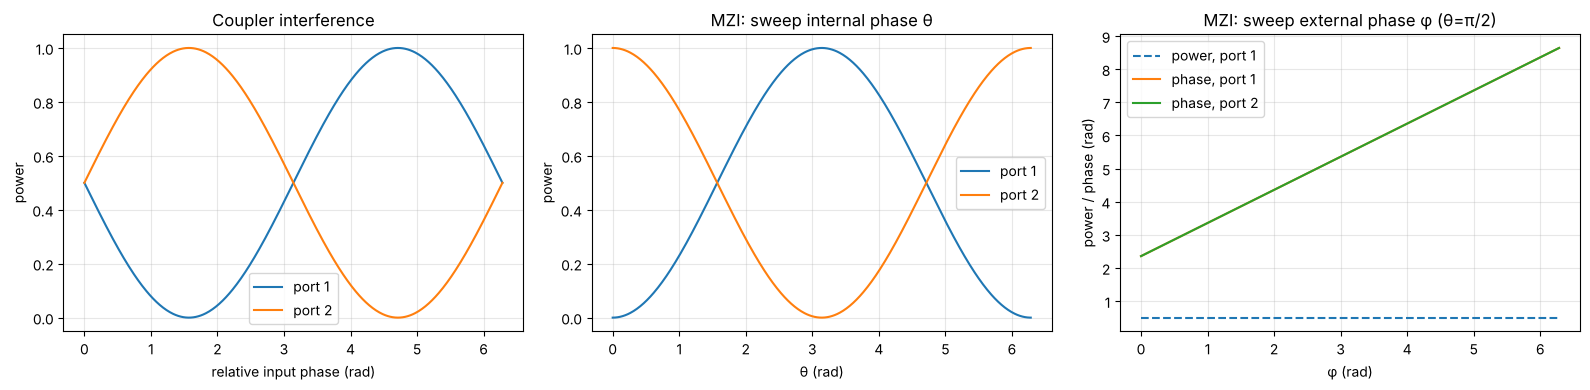

In [3]:
E_out = coupler() @ np.array([1, 0], dtype=complex)
print("Coupler output field :", E_out)
print("Output powers        :", np.abs(E_out)**2, " total =", np.sum(np.abs(E_out)**2))

x = np.linspace(0, 2*np.pi, 500)

# (a) two equal beams interfering in a coupler
E = np.stack([np.full(x.shape, 1/np.sqrt(2), dtype=complex), np.exp(1j*x)/np.sqrt(2)])
pw_c = np.abs(coupler() @ E)**2

# (b) MZI power vs internal phase theta, input in port 1
T_th = np.array([mzi(t, 0.0) for t in x])
pw_th = np.abs(T_th[:, :, 0])**2

# (c) effect of the external phase phi (theta = pi/2)
T_ph = np.array([mzi(np.pi/2, p) for p in x])
pw_ph = np.abs(T_ph[:, :, 0])**2
ph_ph = np.unwrap(np.angle(T_ph[:, :, 0]), axis=0)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(x, pw_c[0], label="port 1"); ax[0].plot(x, pw_c[1], label="port 2")
ax[0].set(title="Coupler interference", xlabel="relative input phase (rad)", ylabel="power")
ax[1].plot(x, pw_th[:, 0], label="port 1"); ax[1].plot(x, pw_th[:, 1], label="port 2")
ax[1].set(title="MZI: sweep internal phase θ", xlabel="θ (rad)", ylabel="power")
ax[2].plot(x, pw_ph[:, 0], "--", label="power, port 1")
ax[2].plot(x, ph_ph[:, 0], label="phase, port 1"); ax[2].plot(x, ph_ph[:, 1], label="phase, port 2")
ax[2].set(title="MZI: sweep external phase φ (θ=π/2)", xlabel="φ (rad)", ylabel="power / phase (rad)")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

## 2. Nulling one element: optimiser → closed form

To send `[a, b] → [r, 0]` the original notebook ran BFGS from a hand-picked starting point. The MZI algebra gives the answer directly:

`B P(θ) B = i e^{iθ/2} [[sin θ/2, cos θ/2],[cos θ/2, −sin θ/2]]`, so the second output vanishes when `tan(θ/2) = |a|/|b|` and `φ = arg b − arg a`.

In [4]:
import time
from scipy.optimize import minimize

a, b = 0.6 + 0.3j, 0.4 - 0.2j
v = np.array([a, b])

# --- old way: numerical optimisation ---------------------------------------
obj = lambda p: np.abs((mzi(p[0], p[1]) @ v)[1])**2
t0 = time.perf_counter()
res = minimize(obj, x0=[np.pi/2, 0], method="BFGS", tol=1e-12)
t_bfgs = time.perf_counter() - t0

# --- new way: closed form ---------------------------------------------------
t0 = time.perf_counter()
for _ in range(1000):
    th, ph = mzi_null(a, b, which=1)
t_cf = (time.perf_counter() - t0) / 1000

out = mzi(th, ph) @ v
print(f"BFGS        : theta={res.x[0]:.6f} phi={res.x[1]:.6f}  residual power={res.fun:.2e}  ({t_bfgs*1e3:.2f} ms)")
print(f"closed form : theta={th:.6f} phi={ph:.6f}  residual power={abs(out[1])**2:.2e}  ({t_cf*1e6:.1f} µs)")
print("output vector      :", out)
print("input / output power:", np.sum(abs(v)**2), np.sum(abs(out)**2))

# The surviving amplitude has an arbitrary phase; an output phase shifter makes it real & positive
T_fix, (th, ph, gam) = optical_elimination(a, b)
print("\nafter output-phase correction  gamma = %.6f" % gam)
print("corrected output   :", T_fix @ v, "  expected |v| =", np.linalg.norm(v))
print("unitarity error    :", np.linalg.norm(T_fix.conj().T @ T_fix - np.eye(2)))

BFGS        : theta=1.965587 phi=-0.927295  residual power=1.67e-17  (2.48 ms)
closed form : theta=1.965587 phi=-0.927295  residual power=3.08e-33  (3.1 µs)
output vector      : [-0.4+0.7j  0. -0.j ]
input / output power: 0.65 0.6500000000000001

after output-phase correction  gamma = -2.089942
corrected output   : [0.8062+0.j 0.    -0.j]   expected |v| = 0.806225774829855
unitarity error    : 3.1916024142452907e-16


## 3. Step by step: a 3×3 unitary (seed 42, same matrix as before)

Eliminate `U[2,0]`, `U[1,0]`, `U[2,1]` with three optical blocks; the result is a diagonal matrix of phases `D`, and `U = G₁† G₂† G₃† D`.

Original U:
 [[ 0.1941-0.5434j -0.4418-0.1534j  0.4693+0.4776j]
 [ 0.5992+0.0421j -0.419 +0.6237j -0.1979-0.1885j]
 [ 0.0814-0.5474j -0.1566-0.4384j -0.356 -0.5918j]] 

Final diagonal matrix:
 [[ 1.    -0.j      0.    -0.j     -0.    -0.j    ]
 [ 0.    -0.j      1.    +0.j     -0.    +0.j    ]
 [ 0.    +0.j     -0.    +0.j     -0.9383+0.3459j]]

Reconstruction error: 3.2994422272027814e-16

Optical phase parameters:
Block 1: theta=1.652588, phi=-1.493194, gamma=-0.973985
Block 2: theta=1.230191, phi=1.227712, gamma=-2.185892
Block 3: theta=1.219470, phi=-3.599919, gamma=0.813215

max deviation from the original notebook's parameters (mod 2π): 5.0e-07


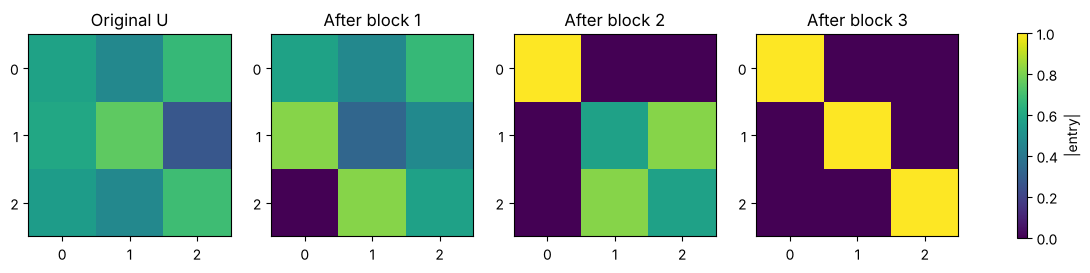

In [5]:
U3 = random_unitary(3, 42)
print("Original U:\n", U3, "\n")

M, history, blocks, params = U3.copy(), [U3.copy()], [], []
for r1, r2, c in [(1, 2, 0), (0, 1, 0), (1, 2, 1)]:
    T, p = optical_elimination(M[r1, c], M[r2, c])
    G = embed(T, 3, r1)
    M = G @ M
    blocks.append(G); params.append(p); history.append(M.copy())

D = M
U3_rec = blocks[0].conj().T @ blocks[1].conj().T @ blocks[2].conj().T @ D
print("Final diagonal matrix:\n", D)
print("\nReconstruction error:", np.linalg.norm(U3 - U3_rec))
print("\nOptical phase parameters:")
for i, (th, ph, ga) in enumerate(params, 1):
    print(f"Block {i}: theta={th:.6f}, phi={ph:.6f}, gamma={ga:.6f}")

# regression check against the original 'from scratch' notebook output
ref = [(1.652588, -1.493194, -0.973985), (1.230191, 1.227712, -2.185892), (1.219470, -3.599919, 0.813215)]
wrap = lambda x: (x + np.pi) % (2*np.pi) - np.pi
dev = max(abs(wrap(np.array(p) - np.array(r))).max() for p, r in zip(params, ref))
print("\nmax deviation from the original notebook's parameters (mod 2π): %.1e" % dev)
assert dev < 2e-6

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, mat, t in zip(axes, history, ["Original U", "After block 1", "After block 2", "After block 3"]):
    im = ax.imshow(np.abs(mat), vmin=0, vmax=1, cmap="viridis"); ax.set_title(t)
    ax.set_xticks(range(3)); ax.set_yticks(range(3)); ax.grid(False)
plt.colorbar(im, ax=axes, shrink=0.7, label="|entry|"); plt.show()

## 4. Reck vs Clements for a 4×4 unitary (seed 123, same matrix as before)

Both return a `Mesh` with identical format. Reck nulls column by column (triangle, depth `2N−3`); Clements alternates right/left eliminations and then pushes the diagonal through the left-hand MZIs with the closed-form `factor_2x2` (rectangle, depth `N`).

mesh       #MZI  depth   recon error   fidelity
Reck          6      5      1.90e-15   1.000000
Clements      6      4      1.65e-15   1.000000

Clements parameters (light order: layer 0 first)
 layer  modes     theta     phi
    0   (2,3)    0.6159   5.6293
    0   (0,1)    2.3180   5.7190
    1   (1,2)    0.0343   1.7256
    2   (2,3)    0.7343   5.3448
    2   (0,1)    1.2559   2.6393
    3   (1,2)    2.1046   5.9218
output phases alpha: [ 1.4173  2.1446 -1.0926  0.1227]


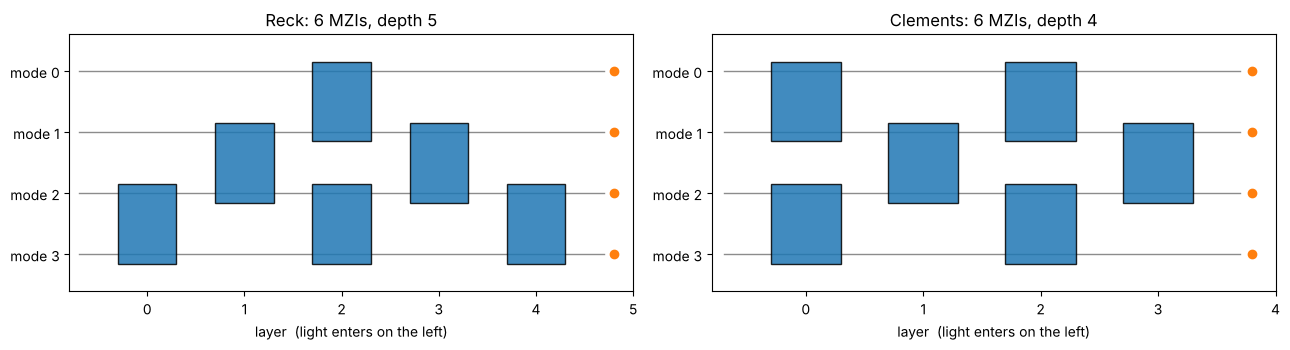

In [6]:
U4 = random_unitary(4, 123)
meshes = {"Reck": decompose_reck(U4), "Clements": decompose_clements(U4)}

print(f"{'mesh':9s} {'#MZI':>5s} {'depth':>6s} {'recon error':>13s} {'fidelity':>10s}")
for name, m in meshes.items():
    A = m.matrix()
    print(f"{name:9s} {m.K:5d} {m.depth:6d} {np.linalg.norm(U4 - A):13.2e} {float(fidelity(U4, A)):10.6f}")

m = meshes["Clements"]
print("\nClements parameters (light order: layer 0 first)")
print(" layer  modes     theta     phi")
for k in np.argsort(m.layers(), kind="stable"):
    print(f"  {m.layers()[k]:3d}   ({m.modes[k]},{m.modes[k]+1})   {m.thetas[k]:7.4f}  {m.phis[k]:7.4f}")
print("output phases alpha:", m.alphas)

def draw_mesh(ax, mesh, title):
    n, L = mesh.n, mesh.layers()
    for i in range(n):
        ax.plot([-0.7, mesh.depth - 0.3], [n-1-i]*2, color="0.55", lw=1, zorder=1)
        ax.plot(mesh.depth - 0.2, n-1-i, "o", color="tab:orange", zorder=2)     # output phase screen
    for mm, l in zip(mesh.modes, L):
        ax.add_patch(plt.Rectangle((l-0.3, n-2-mm-0.15), 0.6, 1.3, fc="tab:blue", ec="k", alpha=0.85, zorder=3))
    ax.set(title=title, xlabel="layer  (light enters on the left)", xlim=(-0.8, mesh.depth), ylim=(-0.6, n-0.4))
    ax.set_yticks(range(n)); ax.set_yticklabels([f"mode {n-1-y}" for y in range(n)]); ax.grid(False)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for a, (name, mm) in zip(ax, meshes.items()):
    draw_mesh(a, mm, f"{name}: {mm.K} MZIs, depth {mm.depth}")
plt.tight_layout(); plt.show()

## 5. Insertion loss

**Loss model** (all numbers are *positive* dB): every coupler transmits `10^(−Lc/10)` of the power, every phase shifter attenuates its arm by `10^(−Lp/10)`. The shortcut `mzi_loss_dB = x` puts `x` dB of coupler loss on each MZI (`x/2` per coupler).

This is exactly the model hidden in the original `pnn` run (`Lp_dB = Lc_dB = −x`): I fitted its saved outputs and they are reproduced to 6 digits for Clements (see the regression table below).

Clements, loss per MZI (dB) | transmission (new / original) | fidelity (new / original)
                       0.00 | 1.000000 / 1.000000            | 1.000000 / 1.000000
                       0.10 | 0.933313 / 0.933313            | 0.999969 / 0.999969
                       0.30 | 0.813290 / 0.813290            | 0.999717 / 0.999717
                       0.50 | 0.709059 / 0.709059            | 0.999215 / 0.999215
                       1.00 | 0.504350 / 0.504350            | 0.996857 / 0.996857
max |difference| = 4.3e-07  -> identical to the original

At 1 dB per MZI:
  Clements  transmission 0.504350  fidelity 0.996857  error 0.587306   (original: 0.504350 / 0.996857 / 0.587306)
  Reck      transmission 0.511461  fidelity 0.989703  error 0.595026   (original: 0.510224 / 0.991097 / 0.593291)


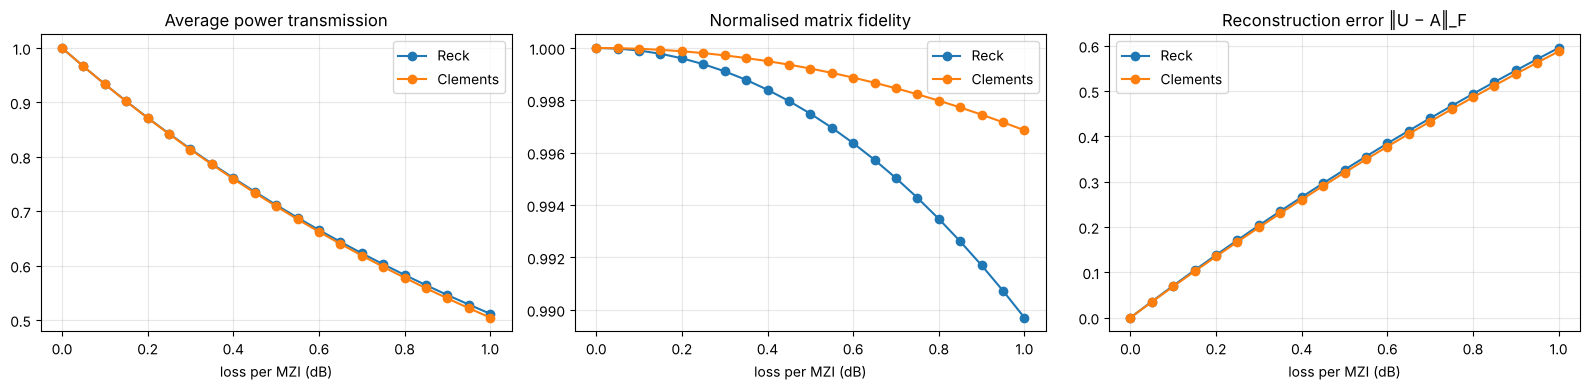

In [7]:
losses = np.linspace(0, 1, 21)
res = {n: {"T": [], "F": [], "E": [], "U": []} for n in meshes}
for n, mm in meshes.items():
    for l in losses:
        A = mm.matrix(mzi_loss_dB=l)
        res[n]["T"].append(float(transmission(A))); res[n]["F"].append(float(fidelity(U4, A)))
        res[n]["E"].append(np.linalg.norm(U4 - A)); res[n]["U"].append(float(unitarity_error(A)))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for n in meshes:
    ax[0].plot(losses, res[n]["T"], "o-", label=n)
    ax[1].plot(losses, res[n]["F"], "o-", label=n)
    ax[2].plot(losses, res[n]["E"], "o-", label=n)
for a, t in zip(ax, ["Average power transmission", "Normalised matrix fidelity", "Reconstruction error ‖U − A‖_F"]):
    a.set(title=t, xlabel="loss per MZI (dB)"); a.legend()
plt.tight_layout(); plt.show()

# ---- regression check against the original notebook's saved numbers ----------------------------
ref_clem = {0.0: (1.0, 1.0), 0.1: (0.933313, 0.999969), 0.3: (0.813290, 0.999717),
            0.5: (0.709059, 0.999215), 1.0: (0.504350, 0.996857)}
print("Clements, loss per MZI (dB) | transmission (new / original) | fidelity (new / original)")
worst = 0
for l, (T0, F0) in ref_clem.items():
    A = meshes["Clements"].matrix(mzi_loss_dB=l)
    T1, F1 = float(transmission(A)), float(fidelity(U4, A))
    worst = max(worst, abs(T1 - T0), abs(F1 - F0))
    print(f"{l:27.2f} | {T1:.6f} / {T0:.6f}            | {F1:.6f} / {F0:.6f}")
assert worst < 1e-6
print(f"max |difference| = {worst:.1e}  -> identical to the original")

A1 = meshes["Clements"].matrix(mzi_loss_dB=1.0)
print("\nAt 1 dB per MZI:")
print("  Clements  transmission %.6f  fidelity %.6f  error %.6f" % (transmission(A1), fidelity(U4, A1), np.linalg.norm(U4 - A1)),
      "  (original: 0.504350 / 0.996857 / 0.587306)")
A1r = meshes["Reck"].matrix(mzi_loss_dB=1.0)
print("  Reck      transmission %.6f  fidelity %.6f  error %.6f" % (transmission(A1r), fidelity(U4, A1r), np.linalg.norm(U4 - A1r)),
      "  (original: 0.510224 / 0.991097 / 0.593291)")

**Reading the table.** The Clements numbers are identical to the original. For Reck the numbers are close but not identical: a Reck triangle can be built in several equivalent orientations/conventions, and `pnn`'s source is not part of the notebooks, so I cannot match its exact arrangement. For this single 4×4 matrix the Reck variants I tried give transmission 0.503–0.511 and fidelity 0.990–0.998 at 1 dB, i.e. **for one matrix, the Reck-vs-Clements fidelity difference depends on the orientation.** The scaling study in §7 averages over many unitaries and gives a convention-independent answer.

## 6. Random phase-setting errors

Each MZI's internal phase θ and external phase φ get independent Gaussian errors of standard deviation σ (the output phases α stay ideal, as in the original). The Monte-Carlo loop is now one batched call, so we can afford **5 000 trials**, report standard errors, and use the *same* noise draws for both meshes (a paired comparison with much less variance).

At σ = 0.2 rad (5000 trials):
  Reck      mean fidelity 0.9142  std 0.0457  s.e. of mean 0.0006
  Clements  mean fidelity 0.9146  std 0.0467  s.e. of mean 0.0007
  paired difference Clements - Reck = +0.0003 ± 0.0007 (s.e.)
  original notebook (200 trials, pnn conventions): Reck 0.8422 ± 0.0738, Clements 0.8519 ± 0.0662


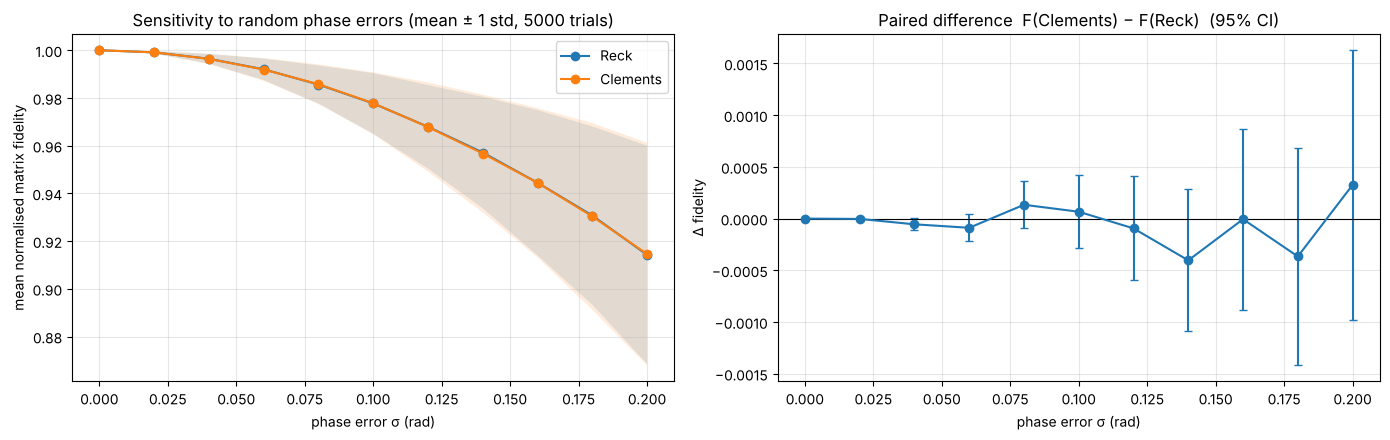

In [8]:
sigmas = np.linspace(0, 0.2, 11)
trials = 5000
rng = np.random.default_rng(2026)
K = meshes["Reck"].K                       # both meshes have N(N-1)/2 MZIs -> same noise array

mean = {n: [] for n in meshes}; std = {n: [] for n in meshes}
dmean, dsem = [], []
for s in sigmas:
    eps = rng.normal(size=(trials, 2, K))                  # common random numbers
    F = {}
    for n, mm in meshes.items():
        F[n] = fidelity(U4, mm.matrix(thetas=mm.thetas + s*eps[:, 0], phis=mm.phis + s*eps[:, 1]))
        mean[n].append(F[n].mean()); std[n].append(F[n].std())
    d = F["Clements"] - F["Reck"]
    dmean.append(d.mean()); dsem.append(d.std() / np.sqrt(trials))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for n in meshes:
    mu, sd = np.array(mean[n]), np.array(std[n])
    ax[0].plot(sigmas, mu, "o-", label=n); ax[0].fill_between(sigmas, mu - sd, mu + sd, alpha=0.15)
ax[0].set(title="Sensitivity to random phase errors (mean ± 1 std, 5000 trials)",
          xlabel="phase error σ (rad)", ylabel="mean normalised matrix fidelity"); ax[0].legend()
dm, ds = np.array(dmean), np.array(dsem)
ax[1].errorbar(sigmas, dm, yerr=1.96*ds, fmt="o-", capsize=3)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(title="Paired difference  F(Clements) − F(Reck)  (95% CI)", xlabel="phase error σ (rad)", ylabel="Δ fidelity")
plt.tight_layout(); plt.show()

print("At σ = 0.2 rad (5000 trials):")
for n in meshes:
    print(f"  {n:9s} mean fidelity {mean[n][-1]:.4f}  std {std[n][-1]:.4f}  s.e. of mean {std[n][-1]/np.sqrt(trials):.4f}")
print(f"  paired difference Clements - Reck = {dm[-1]:+.4f} ± {ds[-1]:.4f} (s.e.)")
print("  original notebook (200 trials, pnn conventions): Reck 0.8422 ± 0.0738, Clements 0.8519 ± 0.0662")

**What is and is not preserved.** The *conclusion* of the original experiment is preserved: for a 4×4 mesh the two architectures are practically equally tolerant to random phase errors (the paired difference is zero within statistical error; the original 0.01 gap between them is about the size of the Monte-Carlo noise of 200 trials, s.e. ≈ 0.005 each). The *absolute* fidelity level is **not** reproduced: the original numbers (≈ 0.84–0.85 at σ = 0.2) are lower than the 0.91 obtained here. Here σ is the error on each *physical* phase shifter; `pnn` stores its own θ/φ variables and its source is not in the notebooks, so I could not establish how its parameters map onto the physical shifters. A different scaling (for example θ stored as half the internal phase) would change the effective error and could explain the gap, but I could not confirm that.

## 7. New: scaling with mesh size (averaged over Haar-random unitaries)

Loss: 0.1 dB per MZI. Phase noise: σ = 0.02 rad on every shifter (100 trials per matrix). Mean over 6 random unitaries per size.

(computed in 0.9 s)

  N |  depth R/C |   transmission R / C |   fidelity (loss) R / C |   fidelity (noise) R / C
  4 |    5 / 4    |    0.9334 / 0.9333    |     0.9999 / 1.0000     |     0.9992 / 0.9991    
  8 |   13 / 8    |    0.8524 / 0.8513    |     0.9993 / 0.9999     |     0.9975 / 0.9976    
 16 |   29 / 16   |    0.7140 / 0.7082    |     0.9958 / 0.9998     |     0.9944 / 0.9944    
 32 |   61 / 32   |    0.5092 / 0.4900    |     0.9806 / 0.9997     |     0.9881 / 0.9881    


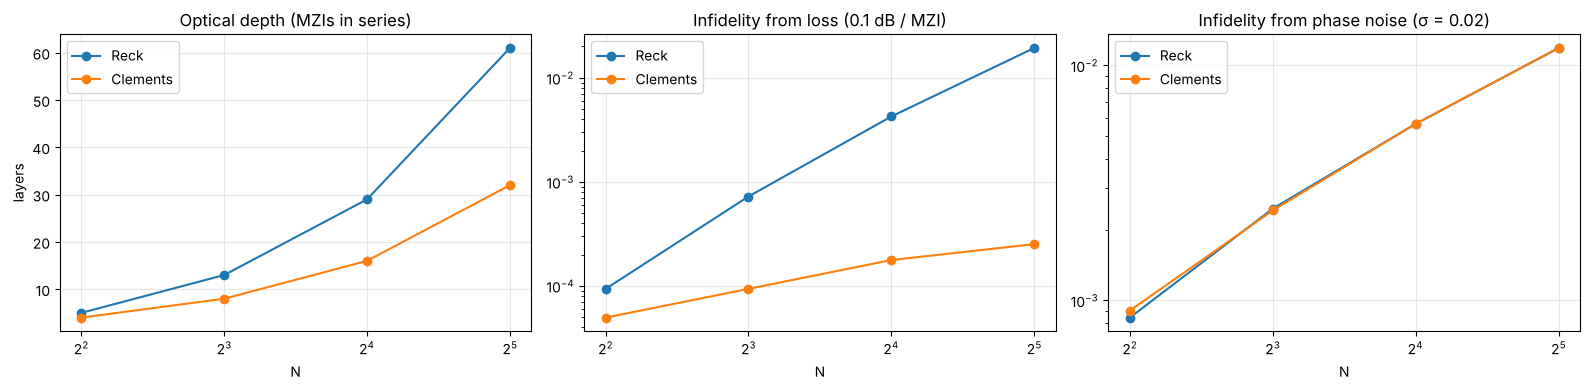

In [9]:
import time
rng = np.random.default_rng(7)
sizes = [4, 8, 16, 32]
tab = {n: {k: [] for k in ("depth", "T", "Floss", "Fnoise")} for n in ("Reck", "Clements")}
t0 = time.time()
for N in sizes:
    acc = {n: {k: [] for k in tab[n]} for n in tab}
    for _ in range(6):
        U = random_unitary(N, rng)
        for n, dec in (("Reck", decompose_reck), ("Clements", decompose_clements)):
            mm = dec(U); A = mm.matrix(mzi_loss_dB=0.1)
            eps = rng.normal(size=(100, 2, mm.K))
            Fn = fidelity(U, mm.matrix(thetas=mm.thetas + 0.02*eps[:, 0], phis=mm.phis + 0.02*eps[:, 1])).mean()
            for k, v in (("depth", mm.depth), ("T", float(transmission(A))), ("Floss", float(fidelity(U, A))), ("Fnoise", Fn)):
                acc[n][k].append(v)
    for n in tab:
        for k in tab[n]:
            tab[n][k].append(np.mean(acc[n][k]))
print(f"(computed in {time.time()-t0:.1f} s)\n")
print(f"{'N':>3s} | {'depth R/C':>10s} | {'transmission R / C':>20s} | {'fidelity (loss) R / C':>23s} | {'fidelity (noise) R / C':>24s}")
for i, N in enumerate(sizes):
    R, C = tab["Reck"], tab["Clements"]
    print(f"{N:3d} | {R['depth'][i]:4.0f} / {C['depth'][i]:<4.0f} | {R['T'][i]:9.4f} / {C['T'][i]:<9.4f} | "
          f"{R['Floss'][i]:10.4f} / {C['Floss'][i]:<10.4f} | {R['Fnoise'][i]:10.4f} / {C['Fnoise'][i]:<10.4f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for n in tab:
    ax[0].plot(sizes, tab[n]["depth"], "o-", label=n)
    ax[1].plot(sizes, 1 - np.array(tab[n]["Floss"]), "o-", label=n)
    ax[2].plot(sizes, 1 - np.array(tab[n]["Fnoise"]), "o-", label=n)
ax[0].set(title="Optical depth (MZIs in series)", xlabel="N", ylabel="layers")
ax[1].set(title="Infidelity from loss (0.1 dB / MZI)", xlabel="N", yscale="log")
ax[2].set(title="Infidelity from phase noise (σ = 0.02)", xlabel="N", yscale="log")
for a in ax: a.set_xscale("log", base=2); a.legend()
plt.tight_layout(); plt.show()

Clements' rectangular layout is balanced: every input→output path crosses nearly the same number of MZIs, so uniform loss is almost a global scale factor and the *shape* of the matrix is preserved (fidelity ≈ 1 even at N = 32), while Reck's unequal path lengths distort it. Sensitivity to random phase errors is essentially the same, because both use the same number of phase shifters. One trade-off is visible in the table: Reck has a few very short paths, so its *average* transmission is slightly higher (0.509 vs 0.490 at N = 32), but the unequal losses are what degrade its fidelity.

## 8. Validation

Reconstruction error for random unitaries (N = 2…16, 20 each) and for degenerate matrices where naive code often divides by zero (identity, permutations, DFT).

In [10]:
worst = {"Reck": 0.0, "Clements": 0.0}
for N in range(2, 17):
    for s in range(20):
        U = random_unitary(N, 1000*N + s)
        for n, dec in (("Reck", decompose_reck), ("Clements", decompose_clements)):
            mm = dec(U)
            assert mm.K == N*(N-1)//2
            worst[n] = max(worst[n], np.linalg.norm(U - mm.matrix()))
print("worst reconstruction error over 300 random unitaries (N = 2..16):")
for n, w in worst.items(): print(f"  {n:9s} {w:.2e}")

special = {"identity": np.eye(5), "cyclic shift": np.eye(5)[[1, 2, 3, 4, 0]], "pair swaps": np.eye(4)[[1, 0, 3, 2]],
           "anti-diagonal": np.eye(4)[::-1], "DFT-6": np.fft.fft(np.eye(6)) / np.sqrt(6)}
print("\nspecial matrices:")
for nm, U in special.items():
    e = [np.linalg.norm(U - dec(U).matrix()) for dec in (decompose_reck, decompose_clements)]
    print(f"  {nm:14s} Reck {e[0]:.1e}   Clements {e[1]:.1e}")
    assert max(e) < 1e-12
assert max(worst.values()) < 1e-12
print("\nall checks passed")

worst reconstruction error over 300 random unitaries (N = 2..16):
  Reck      2.83e-14
  Clements  1.21e-14

special matrices:
  identity       Reck 2.2e-15   Clements 2.1e-15
  cyclic shift   Reck 2.1e-15   Clements 2.0e-15
  pair swaps     Reck 1.4e-15   Clements 1.4e-15
  anti-diagonal  Reck 1.3e-15   Clements 1.3e-15
  DFT-6          Reck 3.2e-15   Clements 2.9e-15

all checks passed
